# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Rasya Gonawi | 5054251032 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

from pathlib import Path
import hashlib
import json
import platform

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, log_loss, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

tf.keras.utils.set_random_seed(42)

In [2]:
%matplotlib inline
SEED = 42
THRESHOLD = 0.5
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "churn" / "Churn_Modelling.csv"
RESULT_DIR = ROOT / "hasil" / "tugas1"
MODEL_DIR = ROOT / "models" / "tugas1"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

display(pd.Series({
    "TensorFlow": tf.__version__, "Keras": keras.__version__,
    "Scikit-learn": sklearn.__version__,
    "Perangkat": "GPU" if tf.config.list_physical_devices("GPU") else "CPU",
}, name="Lingkungan eksperimen").to_frame())

,Lingkungan eksperimen
TensorFlow,2.21.0
Keras,3.15.1
Scikit-learn,1.9.1
Perangkat,CPU


In [3]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv(DATA_PATH)
display(df.head())
display(pd.DataFrame({
    "Tipe data": df.dtypes.astype(str),
    "Missing value": df.isna().sum(),
    "Nilai unik": df.nunique(),
}))
display(df.describe().round(2))
print(f"Ukuran data: {df.shape[0]} baris, {df.shape[1]} kolom; "
      f"baris duplikat: {df.duplicated().sum()}.")

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


,Tipe data,Missing value,Nilai unik
RowNumber,int64,0,10000
CustomerId,int64,0,10000
Surname,str,0,2932
CreditScore,int64,0,460
Geography,str,0,3
Gender,str,0,2
Age,int64,0,70
Tenure,int64,0,11
Balance,float64,0,6382
NumOfProducts,int64,0,4


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


Ukuran data: 10000 baris, 14 kolom; baris duplikat: 0.


,Jumlah,Persentase (%)
Exited,,
Tidak churn,7963,79.63
Churn,2037,20.37


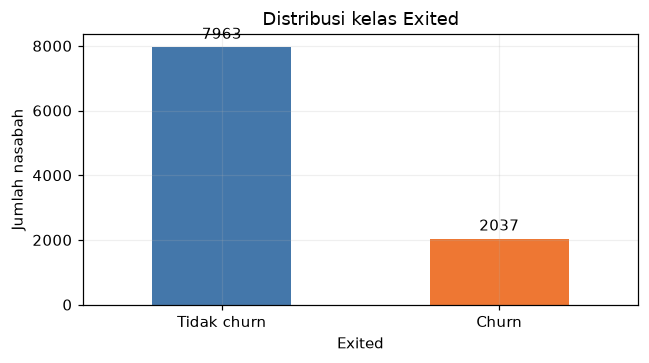

In [4]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

target_counts = df["Exited"].value_counts().sort_index()
target_distribution = pd.DataFrame({
    "Jumlah": target_counts,
    "Persentase (%)": target_counts.div(len(df)).mul(100),
}).rename(index={0: "Tidak churn", 1: "Churn"})
display(target_distribution.round(2))

ax = target_distribution["Jumlah"].plot.bar(
    figsize=(6, 3.4), color=["#4477aa", "#ee7733"], rot=0,
    title="Distribusi kelas Exited",
)
ax.set_ylabel("Jumlah nasabah")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

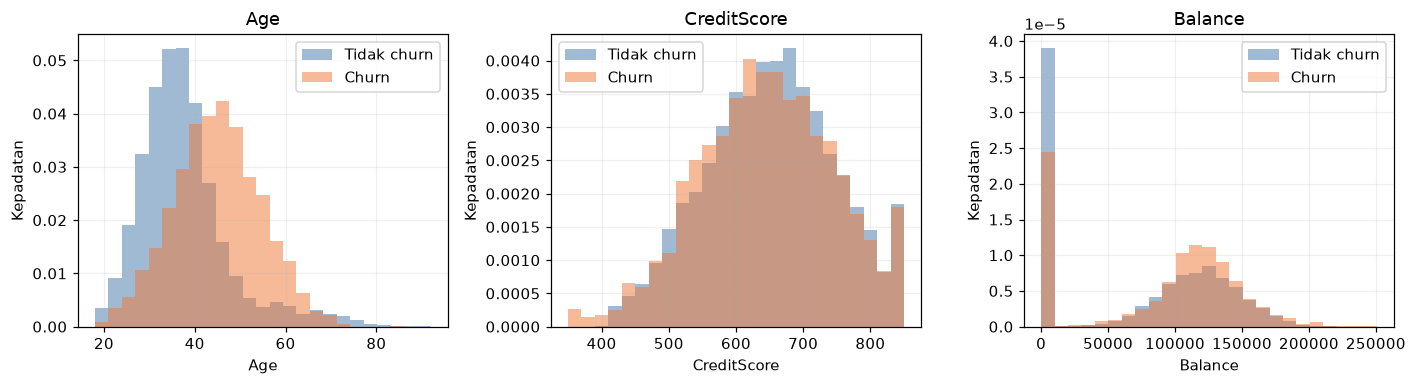

Age        CreditScore          Balance           
         mean median        mean median      mean     median
Exited                                                      
0       37.41   36.0      651.85  653.0  72745.30   92072.68
1       44.84   45.0      645.35  646.0  91108.54  109349.29

In [5]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, column in zip(axes, ["Age", "CreditScore", "Balance"]):
    bins = np.histogram_bin_edges(df[column], bins=25)
    for label, color, name in [(0, "#4477aa", "Tidak churn"), (1, "#ee7733", "Churn")]:
        ax.hist(df.loc[df["Exited"] == label, column], bins=bins,
                density=True, alpha=0.5, color=color, label=name)
    ax.set(title=column, xlabel=column, ylabel="Kepadatan")
    ax.legend()
plt.tight_layout()
plt.show()
display(df.groupby("Exited")[["Age", "CreditScore", "Balance"]].agg(["mean", "median"]).round(2))

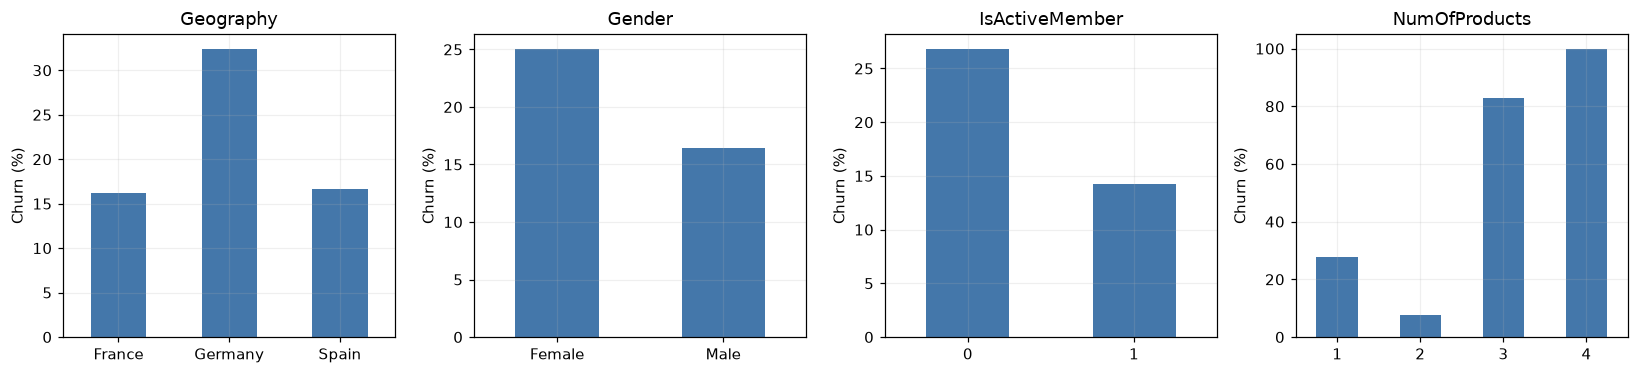

Jumlah  Churn  Churn (%)
Fitur          Kategori                          
Geography      France      5014    810      16.15
               Germany     2509    814      32.44
               Spain       2477    413      16.67
Gender         Female      4543   1139      25.07
               Male        5457    898      16.46
IsActiveMember 0           4849   1302      26.85
               1           5151    735      14.27
NumOfProducts  1           5084   1409      27.71
               2           4590    348       7.58
               3            266    220      82.71
               4             60     60     100.00

In [6]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

category_tables = {}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, column in zip(axes, ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]):
    table = df.groupby(column)["Exited"].agg(Jumlah="count", Churn="sum")
    table["Churn (%)"] = 100 * table["Churn"] / table["Jumlah"]
    category_tables[column] = table
    table["Churn (%)"].plot.bar(ax=ax, color="#4477aa", rot=0)
    ax.set(title=column, xlabel="", ylabel="Churn (%)")
plt.tight_layout()
plt.show()

display(pd.concat(category_tables, names=["Fitur", "Kategori"]).round(2))

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

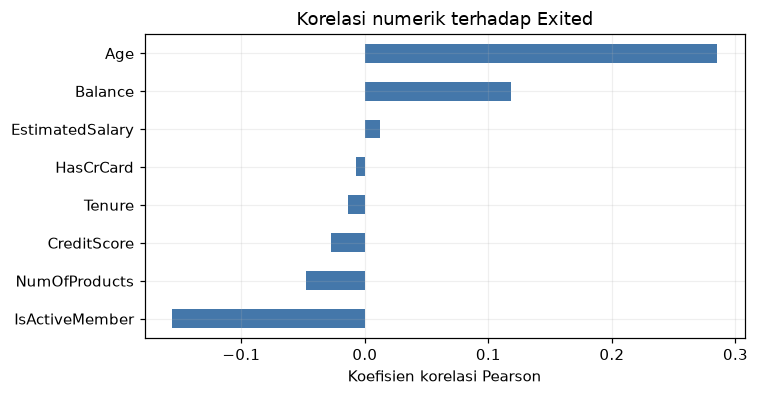

In [7]:
# Hubungan linier fitur numerik dengan target, tanpa kolom identitas.
target_correlation = (
    df.drop(columns=["RowNumber", "CustomerId"]).select_dtypes(include="number")
    .corr()["Exited"].drop("Exited").sort_values()
)
ax = target_correlation.plot.barh(
    figsize=(7, 3.7), color="#4477aa", title="Korelasi numerik terhadap Exited"
)
ax.set_xlabel("Koefisien korelasi Pearson")
plt.tight_layout()
plt.show()

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [8]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber adalah nomor urut; CustomerId dan Surname adalah identitas nasabah.
# Ketiganya tidak digunakan agar model mempelajari karakteristik nasabah.
ignored_columns = ["RowNumber", "CustomerId", "Surname"]
model_data = df.drop(columns=ignored_columns)
display(model_data.head())

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = model_data.drop(columns="Exited")
y = model_data["Exited"]

X_train_raw, X_holdout_raw, y_train, y_holdout = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_holdout_raw, y_holdout, test_size=0.50, stratify=y_holdout, random_state=SEED
)
assert set(X_train_raw.index).isdisjoint(X_val_raw.index)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert set(X_val_raw.index).isdisjoint(X_test_raw.index)

split_table = pd.DataFrame([
    {"Bagian": name, "Jumlah": len(target), "Churn": int(target.sum()),
     "Churn (%)": 100 * target.mean()}
    for name, target in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]
]).set_index("Bagian")
display(split_table.round(2))

,Jumlah,Churn,Churn (%)
Bagian,,,
Training,7000,1426,20.37
Validation,1500,306,20.40
Test,1500,305,20.33


In [10]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

numeric_columns = [column for column in X.columns if column not in ["Geography", "Gender"]]
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("geography", OneHotEncoder(
        drop="first", handle_unknown="ignore", sparse_output=False
    ), ["Geography"]),
    ("gender", OrdinalEncoder(
        categories=[["Female", "Male"]], handle_unknown="use_encoded_value", unknown_value=-1
    ), ["Gender"]),
])
X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out().tolist()
display(pd.DataFrame(X_train[:5], columns=feature_names).round(3))

,numeric__CreditScore,numeric__Age,numeric__Tenure,numeric__Balance,numeric__NumOfProducts,numeric__HasCrCard,numeric__IsActiveMember,numeric__EstimatedSalary,geography__Geography_Germany,geography__Geography_Spain,gender__Gender
0,-0.576,-1.797,-0.349,0.313,-0.912,0.643,-1.035,1.363,0.0,0.0,1.0
1,0.398,2.270,-1.387,-1.224,0.799,0.643,0.967,1.515,0.0,1.0,0.0
2,1.693,-0.756,-1.387,0.682,-0.912,0.643,-1.035,0.039,0.0,0.0,1.0
3,0.740,-1.797,0.342,-1.224,0.799,0.643,-1.035,1.671,0.0,0.0,1.0
4,0.906,-1.986,-0.349,-1.224,0.799,0.643,0.967,-0.899,0.0,0.0,1.0


In [11]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")

X_train = np.asarray(X_train, dtype="float32")
X_val = np.asarray(X_val, dtype="float32")
X_test = np.asarray(X_test, dtype="float32")
y_train = np.asarray(y_train, dtype="float32")
y_val = np.asarray(y_val, dtype="float32")
y_test = np.asarray(y_test, dtype="float32")

assert all(array.dtype == np.float32 and np.isfinite(array).all()
           for array in [X_train, X_val, X_test, y_train, y_val, y_test])
display(pd.DataFrame({
    "Bagian": ["Training", "Validation", "Test"],
    "Bentuk X": [str(X_train.shape), str(X_val.shape), str(X_test.shape)],
    "Bentuk y": [str(y_train.shape), str(y_val.shape), str(y_test.shape)],
    "Tipe data": [str(X_train.dtype), str(X_val.dtype), str(X_test.dtype)],
}).set_index("Bagian"))

,Bentuk X,Bentuk y,Tipe data
Bagian,,,
Training,"(7000, 11)","(7000,)",float32
Validation,"(1500, 11)","(1500,)",float32
Test,"(1500, 11)","(1500,)",float32


# 3. Eksperimen Model

In [12]:
def metric_values(target, probabilities):
    predicted = (probabilities >= THRESHOLD).astype("int32")
    return {
        "Accuracy": accuracy_score(target, predicted),
        "Precision": precision_score(target, predicted, zero_division=0),
        "Recall": recall_score(target, predicted, zero_division=0),
        "F1_churn": f1_score(target, predicted, zero_division=0),
        "ROC_AUC": roc_auc_score(target, probabilities),
        "AP": average_precision_score(target, probabilities),
    }


models, histories, validation_scores = {}, {}, {}
test_probabilities, test_predictions = {}, {}

In [13]:
class TrainingEvaluation(keras.callbacks.Callback):
    # Hitung loss tanpa bobot dan tanpa Dropout untuk membantu analisis kurva.
    def __init__(self):
        super().__init__()
        self.losses, self.accuracies = [], []

    def on_epoch_end(self, epoch, logs=None):
        probabilities = np.asarray(self.model(X_train, training=False)).ravel()
        self.losses.append(log_loss(y_train, probabilities, labels=[0, 1]))
        self.accuracies.append(accuracy_score(y_train, probabilities >= THRESHOLD))


def early_stopping():
    return keras.callbacks.EarlyStopping(
        monitor="val_loss", mode="min", patience=10, restore_best_weights=True
    )


def register_ann(name, model, history, recorder):
    history.history["train_eval_loss"] = recorder.losses
    history.history["train_eval_accuracy"] = recorder.accuracies
    models[name], histories[name] = model, history.history
    probabilities = np.asarray(model(X_val, training=False)).ravel()
    validation_scores[name] = metric_values(y_val, probabilities)
    display(pd.DataFrame([{
        "Model": name, "Epoch": len(history.history["loss"]),
        "Epoch terbaik": int(np.argmin(history.history["val_loss"]) + 1),
        **validation_scores[name],
    }]).set_index("Model").round(4))

In [14]:
def plot_history(history, title):
    values = history.history
    epochs = np.arange(1, len(values["loss"]) + 1)
    best_epoch = int(np.argmin(values["val_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, train_key, val_key, ylabel in [
        (axes[0], "loss", "val_loss", "Binary cross-entropy"),
        (axes[1], "accuracy", "val_accuracy", "Accuracy"),
    ]:
        ax.plot(epochs, values[train_key], color="#4477aa", label="Training (fit)")
        ax.plot(epochs, values[val_key], color="#ee7733", label="Validation")
        ax.axvline(best_epoch, color="gray", linestyle=":", label="Epoch terbaik")
        ax.set(xlabel="Epoch", ylabel=ylabel)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [15]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

logistic = LogisticRegression(max_iter=1000, random_state=SEED)
logistic.fit(X_train, y_train)
models["Logistic Regression"] = logistic
test_probabilities["Logistic Regression"] = logistic.predict_proba(X_test)[:, 1]
test_predictions["Logistic Regression"] = (
    test_probabilities["Logistic Regression"] >= THRESHOLD
).astype("int32")
validation_scores["Logistic Regression"] = metric_values(
    y_val, logistic.predict_proba(X_val)[:, 1]
)
display(pd.DataFrame.from_dict(
    {"Logistic Regression": validation_scores["Logistic Regression"]}, orient="index"
).round(4))

,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
Logistic Regression,0.8107,0.617,0.1895,0.29,0.7846,0.5069


In [16]:
# Learning curve baseline terhadap jumlah sampel training, bukan epoch.
logistic_curve_rows = []
for fraction in [0.1, 0.25, 0.5, 0.75, 1.0]:
    if fraction == 1.0:
        subset_X, subset_y = X_train_raw, y_train
    else:
        subset_X, _, subset_y, _ = train_test_split(
            X_train_raw, y_train, train_size=fraction, stratify=y_train, random_state=SEED
        )
    subset_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=1000, random_state=SEED)),
    ])
    subset_pipeline.fit(subset_X, subset_y)
    train_prob = subset_pipeline.predict_proba(subset_X)[:, 1]
    val_prob = subset_pipeline.predict_proba(X_val_raw)[:, 1]
    logistic_curve_rows.append({
        "Jumlah training": len(subset_y),
        "Train loss": log_loss(subset_y, train_prob),
        "Validation loss": log_loss(y_val, val_prob),
        "Train accuracy": accuracy_score(subset_y, train_prob >= THRESHOLD),
        "Validation accuracy": accuracy_score(y_val, val_prob >= THRESHOLD),
    })
logistic_curve = pd.DataFrame(logistic_curve_rows)
display(logistic_curve.round(4))

,Jumlah training,Train loss,Validation loss,Train accuracy,Validation accuracy
0,700,0.4151,0.4294,0.8129,0.8040
1,1750,0.4397,0.4238,0.8091,0.8100
2,3500,0.4375,0.4206,0.8131,0.8100
3,5250,0.4355,0.4196,0.8137,0.8100
4,7000,0.4344,0.4183,0.8120,0.8107


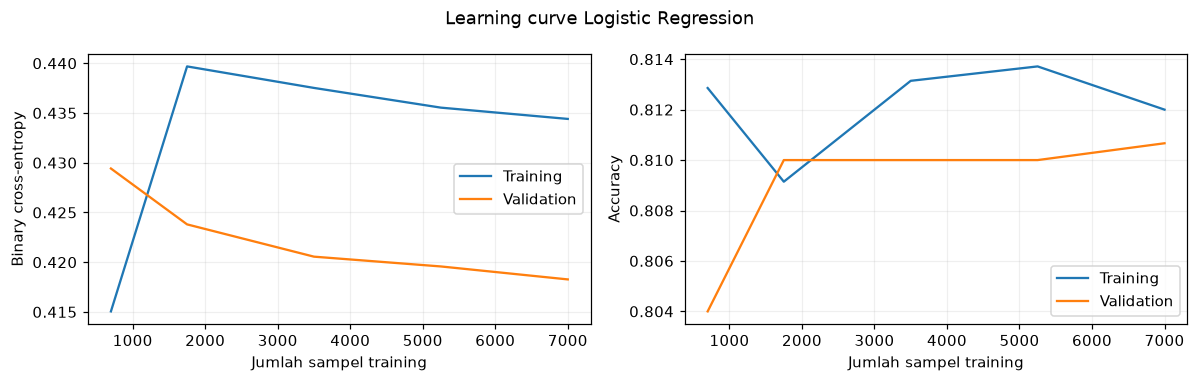

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, train_key, val_key, ylabel in [
    (axes[0], "Train loss", "Validation loss", "Binary cross-entropy"),
    (axes[1], "Train accuracy", "Validation accuracy", "Accuracy"),
]:
    ax.plot(logistic_curve["Jumlah training"], logistic_curve[train_key], label="Training")
    ax.plot(logistic_curve["Jumlah training"], logistic_curve[val_key], label="Validation")
    ax.set(xlabel="Jumlah sampel training", ylabel=ylabel)
    ax.legend()
fig.suptitle("Learning curve Logistic Regression")
plt.tight_layout()
plt.show()

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [18]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

tf.keras.utils.set_random_seed(SEED)
ann_simple = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="ann_sederhana")
ann_simple.summary()

Model: "ann_sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.

ann_simple.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy", metrics=["accuracy"],
)
recorder_simple = TrainingEvaluation()
history = ann_simple.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=100, batch_size=64,
    callbacks=[recorder_simple, early_stopping()], verbose=0,
)
register_ann("ANN sederhana", ann_simple, history, recorder_simple)

,Epoch,Epoch terbaik,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
Model,,,,,,,,
ANN sederhana,100,99,0.866,0.772,0.4869,0.5972,0.8756,0.7105


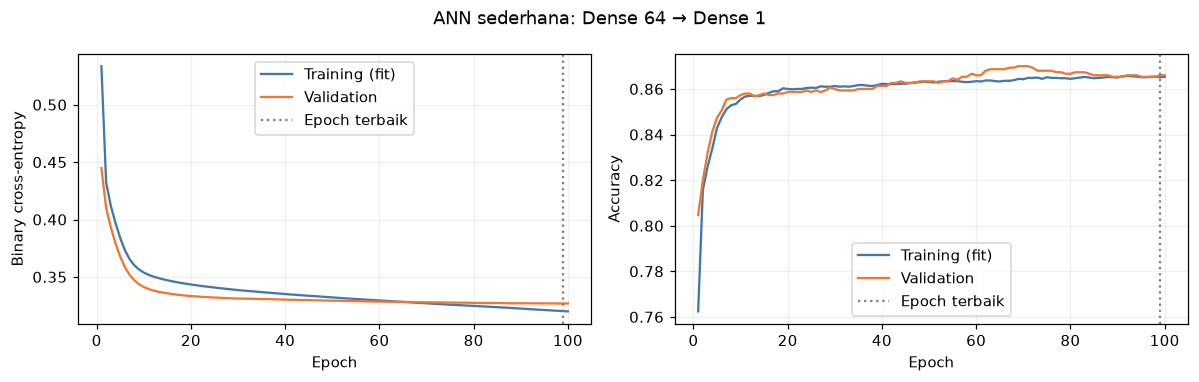

In [20]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].

plot_history(history, "ANN sederhana: Dense 64 → Dense 1")

In [21]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.

test_probabilities["ANN sederhana"] = ann_simple.predict(X_test, verbose=0).ravel()
test_predictions["ANN sederhana"] = (
    test_probabilities["ANN sederhana"] >= THRESHOLD
).astype("int32")

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [22]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.

tf.keras.utils.set_random_seed(SEED)
ann_dropout = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),
], name="ann_dropout")
ann_dropout.summary()

Model: "ann_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

,Epoch,Epoch terbaik,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
Model,,,,,,,,
ANN + Dropout,76,66,0.8693,0.7696,0.5131,0.6157,0.8825,0.7292


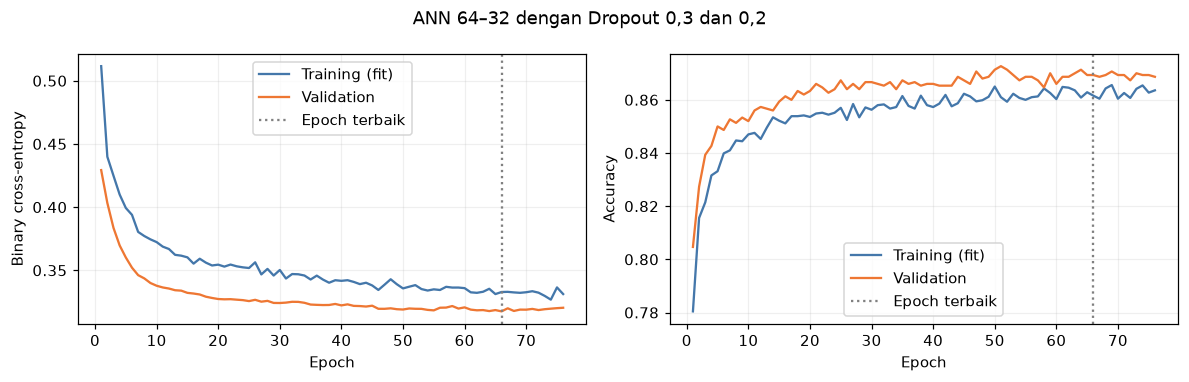

In [23]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

ann_dropout.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy", metrics=["accuracy"],
)
recorder_dropout = TrainingEvaluation()
history_dropout = ann_dropout.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=100, batch_size=64,
    callbacks=[recorder_dropout, early_stopping()], verbose=0,
)
register_ann("ANN + Dropout", ann_dropout, history_dropout, recorder_dropout)
plot_history(history_dropout, "ANN 64–32 dengan Dropout 0,3 dan 0,2")

In [24]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

test_probabilities["ANN + Dropout"] = ann_dropout.predict(X_test, verbose=0).ravel()
test_predictions["ANN + Dropout"] = (
    test_probabilities["ANN + Dropout"] >= THRESHOLD
).astype("int32")

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [25]:
# Pilih arsitektur terbaik dari bagian 3.2 dan 3.3 memakai validation.
base_validation = pd.DataFrame.from_dict({
    name: validation_scores[name] for name in ["ANN sederhana", "ANN + Dropout"]
}, orient="index").sort_values(["F1_churn", "ROC_AUC"], ascending=False)
best_base_name = str(base_validation.index[0])
display(base_validation.round(4))
print(f"Arsitektur untuk eksperimen class weight: {best_base_name}")

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(label): float(weight) for label, weight in zip(classes, weights)}
display(pd.DataFrame({
    "Kelas": classes.astype("int32"),
    "Jumlah training": [int((y_train == label).sum()) for label in classes],
    "Class weight": weights,
}).set_index("Kelas").round(4))

,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
ANN + Dropout,0.8693,0.7696,0.5131,0.6157,0.8825,0.7292
ANN sederhana,0.8660,0.7720,0.4869,0.5972,0.8756,0.7105


Arsitektur untuk eksperimen class weight: ANN + Dropout


,Jumlah training,Class weight
Kelas,,
0,5574,0.6279
1,1426,2.4544


In [26]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.

tf.keras.utils.set_random_seed(SEED)
# clone_model menyalin arsitektur saja, bukan bobot hasil training sebelumnya.
ann_weighted = keras.models.clone_model(models[best_base_name])
ann_weighted.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy", metrics=["accuracy"],
)
ann_weighted.summary()
recorder_weighted = TrainingEvaluation()
history_weighted = ann_weighted.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=100, batch_size=64, class_weight=class_weights,
    callbacks=[recorder_weighted, early_stopping()], verbose=0,
)
register_ann("ANN + Class Weight", ann_weighted, history_weighted, recorder_weighted)

Model: "ann_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

,Epoch,Epoch terbaik,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
Model,,,,,,,,
ANN + Class Weight,56,46,0.8093,0.5221,0.7712,0.6227,0.8797,0.7203


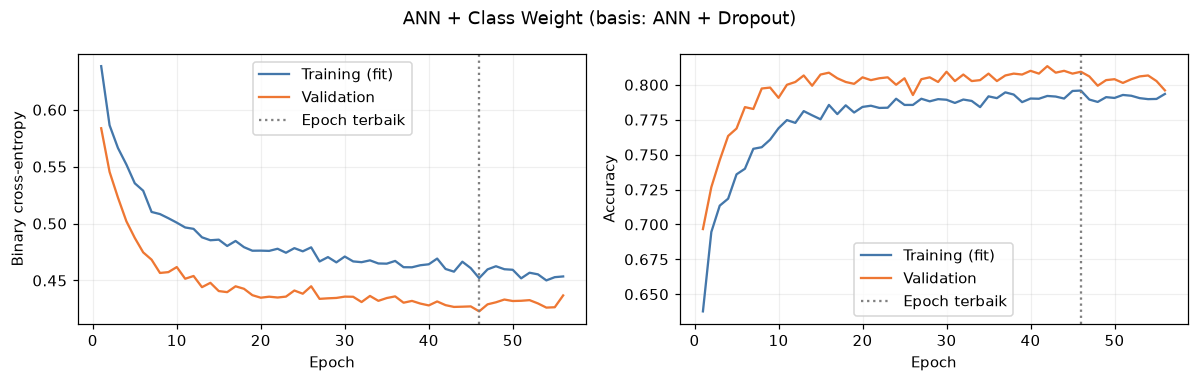

In [27]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(history_weighted, f"ANN + Class Weight (basis: {best_base_name})")
test_probabilities["ANN + Class Weight"] = ann_weighted.predict(X_test, verbose=0).ravel()
test_predictions["ANN + Class Weight"] = (
    test_probabilities["ANN + Class Weight"] >= THRESHOLD
).astype("int32")

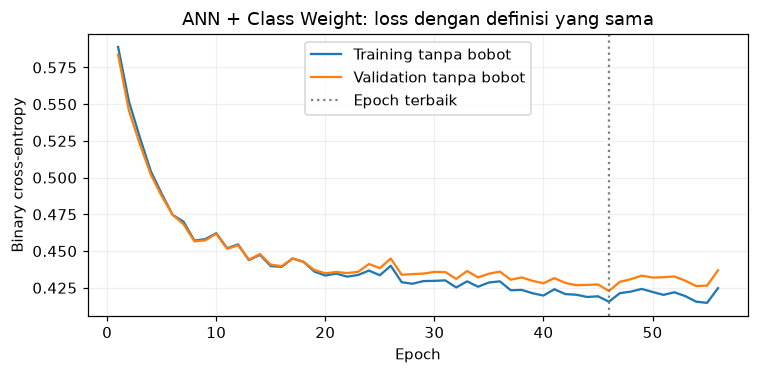

In [28]:
weighted_values = history_weighted.history
epochs = np.arange(1, len(weighted_values["loss"]) + 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(epochs, weighted_values["train_eval_loss"], label="Training tanpa bobot")
ax.plot(epochs, weighted_values["val_loss"], label="Validation tanpa bobot")
ax.axvline(int(np.argmin(weighted_values["val_loss"]) + 1),
           color="gray", linestyle=":", label="Epoch terbaik")
ax.set(title="ANN + Class Weight: loss dengan definisi yang sama",
       xlabel="Epoch", ylabel="Binary cross-entropy")
ax.legend()
plt.tight_layout()
plt.show()

# 4. Evaluasi Model

In [29]:
# Tetapkan model akhir dari validation sebelum membuka metrik test.
validation_table = pd.DataFrame.from_dict(validation_scores, orient="index")
validation_table.index.name = "Model"
validation_ranking = validation_table.sort_values(["F1_churn", "ROC_AUC"], ascending=False)
best_name = str(validation_ranking.index[0])
best_model = models[best_name]
display(validation_ranking.round(4))
print(f"Model akhir berdasarkan F1 validation: {best_name}")

,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
Model,,,,,,
ANN + Class Weight,0.8093,0.5221,0.7712,0.6227,0.8797,0.7203
ANN + Dropout,0.8693,0.7696,0.5131,0.6157,0.8825,0.7292
ANN sederhana,0.8660,0.7720,0.4869,0.5972,0.8756,0.7105
Logistic Regression,0.8107,0.6170,0.1895,0.2900,0.7846,0.5069


Model akhir berdasarkan F1 validation: ANN + Class Weight


In [30]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

test_scores = {
    name: metric_values(y_test, probabilities)
    for name, probabilities in test_probabilities.items()
}
test_table = pd.DataFrame.from_dict(test_scores, orient="index")
test_table.index.name = "Model"
display(test_table.round(4))

,Accuracy,Precision,Recall,F1_churn,ROC_AUC,AP
Model,,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913,0.5131
ANN sederhana,0.8653,0.7754,0.4754,0.5894,0.8602,0.7153
ANN + Dropout,0.8700,0.7835,0.4984,0.6092,0.8670,0.7261
ANN + Class Weight,0.8087,0.5205,0.7508,0.6148,0.8672,0.7299


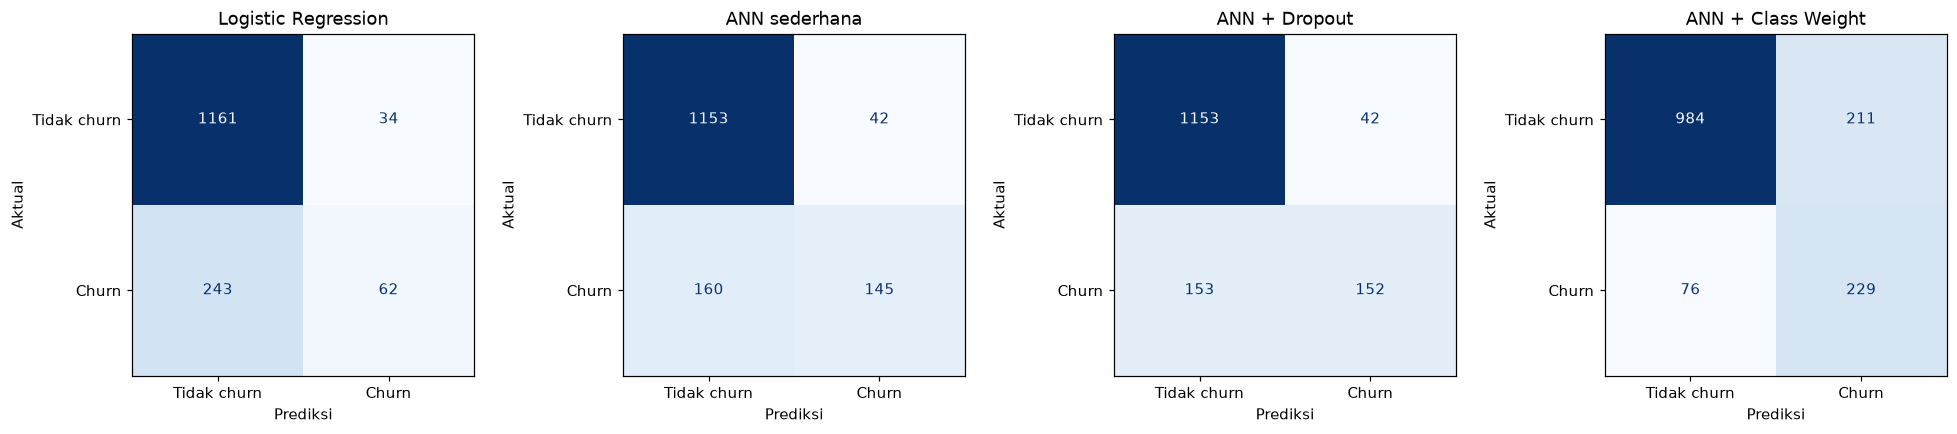

In [31]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
confusion_counts = {}
for ax, (name, predicted) in zip(axes, test_predictions.items()):
    shown = ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1], display_labels=["Tidak churn", "Churn"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    tn, fp, fn, tp = shown.confusion_matrix.ravel()
    confusion_counts[name] = {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}
    ax.set(title=name, xlabel="Prediksi", ylabel="Aktual")
    ax.grid(False)
plt.tight_layout()
plt.show()

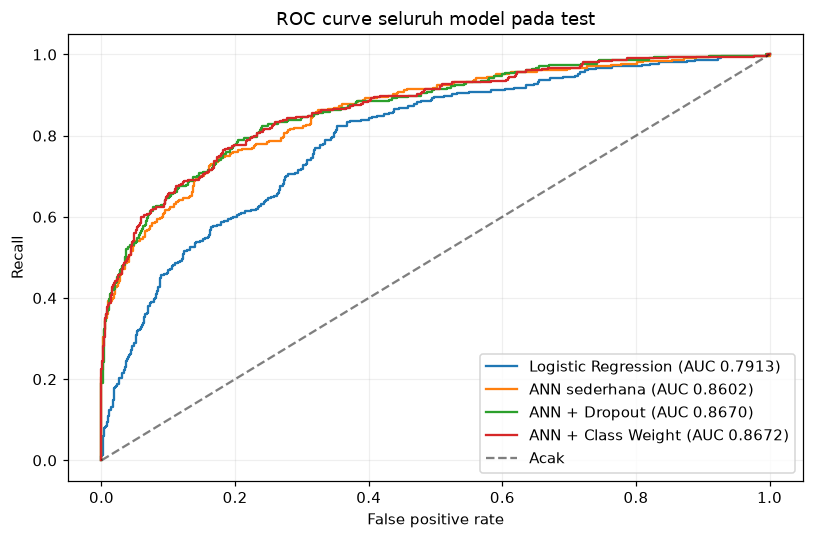

In [32]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

fig, ax = plt.subplots(figsize=(7.5, 5))
for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, label=f"{name} (AUC {test_scores[name]['ROC_AUC']:.4f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Acak")
ax.set(title="ROC curve seluruh model pada test", xlabel="False positive rate", ylabel="Recall")
ax.legend()
plt.tight_layout()
plt.show()

# 5. Menyimpan Model Terbaik

In [33]:
model_is_keras = isinstance(best_model, keras.Model)
model_path = MODEL_DIR / ("model_terbaik.keras" if model_is_keras else "model_terbaik.joblib")
if model_is_keras:
    best_model.save(model_path)
else:
    joblib.dump(best_model, model_path)
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.joblib")

saved_preprocessor = joblib.load(MODEL_DIR / "preprocessor.joblib")
sample_input = saved_preprocessor.transform(X_test_raw.iloc[:10]).astype("float32")
if model_is_keras:
    loaded_model = keras.models.load_model(model_path)
    loaded_probabilities = loaded_model.predict(sample_input, verbose=0).ravel()
else:
    loaded_model = joblib.load(model_path)
    loaded_probabilities = loaded_model.predict_proba(sample_input)[:, 1]
np.testing.assert_allclose(
    loaded_probabilities, test_probabilities[best_name][:10], rtol=1e-5, atol=1e-6
)
print(f"Model disimpan: {model_path.relative_to(ROOT)}")
print("Model dan preprocessor berhasil dimuat ulang; prediksi konsisten.")

Model disimpan: models\tugas1\model_terbaik.keras
Model dan preprocessor berhasil dimuat ulang; prediksi konsisten.


In [34]:
curve_summary_rows = []
for name, values in histories.items():
    i = int(np.argmin(values["val_loss"]))
    curve_summary_rows.append({
        "Model": name, "Epoch terbaik": i + 1, "Epoch dijalankan": len(values["loss"]),
        "Train loss (fit, terbaik)": values["loss"][i],
        "Train loss (evaluasi, terbaik)": values["train_eval_loss"][i],
        "Val loss (terbaik)": values["val_loss"][i],
        "Train accuracy (evaluasi, terbaik)": values["train_eval_accuracy"][i],
        "Val accuracy (terbaik)": values["val_accuracy"][i],
        "Train loss (evaluasi, akhir)": values["train_eval_loss"][-1],
        "Val loss (akhir)": values["val_loss"][-1],
    })
curve_summary = pd.DataFrame(curve_summary_rows).set_index("Model")
display(curve_summary.round(4))

,Epoch terbaik,Epoch dijalankan,"Train loss (fit, terbaik)","Train loss (evaluasi, terbaik)",Val loss (terbaik),"Train accuracy (evaluasi, terbaik)",Val accuracy (terbaik),"Train loss (evaluasi, akhir)",Val loss (akhir)
Model,,,,,,,,,
ANN sederhana,99,100,0.3202,0.3181,0.3269,0.8671,0.8660,0.3178,0.3269
ANN + Dropout,66,76,0.3328,0.3142,0.3175,0.8679,0.8693,0.3115,0.3204
ANN + Class Weight,46,56,0.4521,0.4155,0.4229,0.8106,0.8093,0.4248,0.4369


In [35]:
metadata = {
    "student": {"name": "Rasya Gonawi", "nrp": "5054251032"},
    "selected_model": best_name, "model_file": model_path.name,
    "preprocessor_file": "preprocessor.joblib", "threshold": THRESHOLD,
    "selection_rule": "Maximum validation F1_churn; ROC_AUC as tie breaker",
    "class_weight_base_architecture": best_base_name,
    "target": {"column": "Exited", "labels": {"0": "Tidak churn", "1": "Churn"}},
    "raw_feature_order": X.columns.tolist(), "numeric_columns": numeric_columns,
    "geography_encoding": "OneHotEncoder, drop=first",
    "gender_encoding": {"Female": 0, "Male": 1, "unknown": -1},
    "encoded_feature_order": feature_names, "ignored_columns": ignored_columns,
    "seed": SEED, "class_weights": class_weights,
    "split": {"train": len(y_train), "validation": len(y_val), "test": len(y_test)},
    "validation_metrics": validation_scores[best_name],
    "test_metrics": test_scores[best_name],
    "dataset": "data/churn/Churn_Modelling.csv",
    "dataset_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "template_sha256": hashlib.sha256((ROOT / "1_DL_NRP.ipynb").read_bytes()).hexdigest(),
    "versions": {
        "python": platform.python_version(), "tensorflow": tf.__version__,
        "keras": keras.__version__, "scikit-learn": sklearn.__version__,
        "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__,
    },
    "reload_check": "passed, rtol=1e-5, atol=1e-6 on 10 held-out raw rows",
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
(MODEL_DIR / "requirements.txt").write_text(
    "\n".join(f"{package}=={version}" for package, version in metadata["versions"].items()
              if package != "python") + "\n", encoding="utf-8"
)

94

In [36]:
comparison_table = pd.concat(
    {"Validation": validation_table, "Test": test_table}, names=["Bagian", "Model"]
)
comparison_table.to_csv(RESULT_DIR / "perbandingan_model.csv")
pd.concat([
    pd.DataFrame(values).assign(Model=name, Epoch=lambda table: np.arange(1, len(table) + 1))
    for name, values in histories.items()
], ignore_index=True).to_csv(RESULT_DIR / "riwayat_training.csv", index=False)
logistic_curve.to_csv(RESULT_DIR / "learning_curve_logistic.csv", index=False)

experiment_results = {
    **metadata, "all_validation_metrics": validation_scores,
    "all_test_metrics": test_scores, "test_confusion_counts": confusion_counts,
    "ann_curve_summary": curve_summary.reset_index().to_dict(orient="records"),
    "logistic_curve": logistic_curve.to_dict(orient="records"),
    "dataset_overview": {
        "rows": len(df), "columns": df.shape[1],
        "missing": int(df.isna().sum().sum()), "duplicates": int(df.duplicated().sum()),
        "churn": int(df["Exited"].sum()), "churn_fraction": float(df["Exited"].mean()),
    },
    "eda_numeric_means": df.groupby("Exited")[["Age", "CreditScore", "Balance"]].mean().to_dict(),
    "eda_categories": {
        column: table.reset_index().to_dict(orient="records")
        for column, table in category_tables.items()
    },
    "target_correlation": target_correlation.to_dict(),
}
(RESULT_DIR / "hasil_eksperimen.json").write_text(
    json.dumps(experiment_results, indent=2, ensure_ascii=False), encoding="utf-8"
)
display(pd.DataFrame({"File": [
    str(path.relative_to(ROOT)) for path in sorted(MODEL_DIR.iterdir())
]}))

,File
0,models\tugas1\metadata.json
1,models\tugas1\model_terbaik.keras
2,models\tugas1\preprocessor.joblib
3,models\tugas1\requirements.txt


# 6. Analisis dan Kesimpulan

Data churn tidak seimbang karena hanya 20,37% nasabah yang churn. Logistic Regression memperoleh accuracy 81,53%, tetapi recall churn hanya 20,33% dan F1 0,3092. Kurva training dan validation yang dekat, tetapi pengenalan churn yang lemah dibanding ANN, mengindikasikan keterbatasan model linier pada data ini.

ANN sederhana memperoleh F1 test 0,5894, sedangkan ANN + Dropout 0,6092 dengan accuracy 87,00%. Loss validation minimum ANN sederhana 0,3269 pada epoch 99; kurvanya cenderung mendatar tanpa overfitting yang kuat. ANN + Dropout mencapai minimum 0,3175 pada epoch 66, kemudian validation mulai memburuk meskipun training membaik. Ini menunjukkan overfitting ringan. Penambahan layer dan Dropout memberi perbaikan pada percobaan ini, tetapi pengaruh keduanya belum dipisahkan.

Class weight menggunakan arsitektur ANN + Dropout yang dilatih ulang. Recall test naik dari 49,84% menjadi 75,08%, sedangkan precision turun dari 78,35% menjadi 52,05%. Churn yang terdeteksi meningkat dari 152 menjadi 229, tetapi false positive bertambah dari 42 menjadi 211. Bobot epoch 46 digunakan karena memberikan loss validation terendah. Perbandingan kurvanya memakai loss tanpa bobot agar training dan validation dinilai dengan definisi yang sama.

Model akhir yang dipilih adalah ANN + Class Weight, berdasarkan F1 validation tertinggi 0,6227. Pada test, model ini mencapai accuracy 80,87% dan F1 churn 0,6148. Class weight membantu menemukan lebih banyak churn dengan konsekuensi lebih banyak salah penandaan. Pengujian threshold sesuai biaya kesalahan dan beberapa seed dapat dilakukan berikutnya menggunakan validation.